<a href="https://colab.research.google.com/github/yuvasrisugu2008-maker/ITA0515--COMPUTER-VISION/blob/main/exp%2025.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings


Saving flower.jpg to flower (9).jpg
requirements: Ultralytics requirement ['git+https://github.com/ultralytics/CLIP.git'] not found, attempting AutoUpdate...
Using Python 3.13.18 environment at: /usr
Resolved 18 packages in 589ms
Prepared 2 packages in 2.33s
Installed 2 packages in 1ms
 + clip==1.0 (from git+https://github.com/ultralytics/CLIP.git@7ffa84b3bfa40c42ecc1c77147a855e69cb2dd40)
 + ftfy==6.3.1

requirements: AutoUpdate success ✅ 3.3s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect



100%|████████████████████████████████████████| 338M/338M [00:03<00:00, 109MiB/s]
/usr/local/lib/python3.13/dist-packages/torch/jit/_serialization.py:176: FutureWarning: `torch.jit.load` is deprecated. Please switch to `torch.export`.
  warnings.warn(


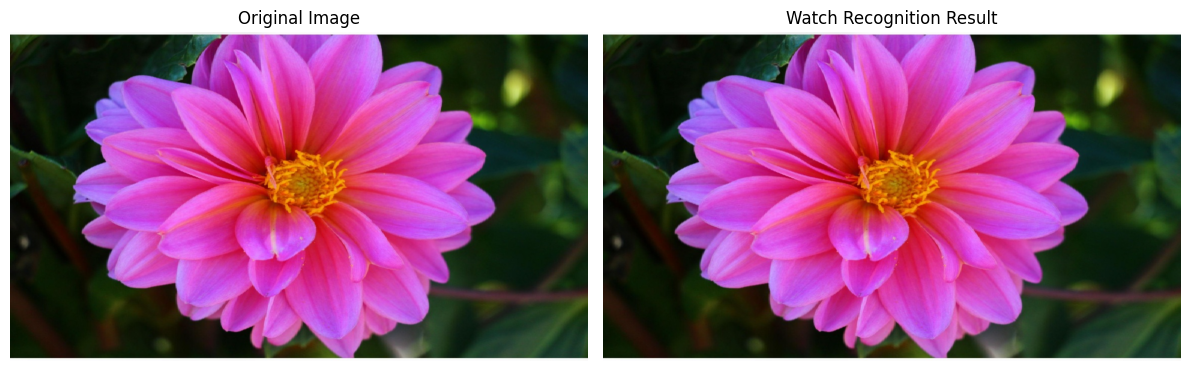

No watch detected. Try another image or adjust the confidence value.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [31]:

# Install required libraries
!pip install -q ultralytics

import cv2
import matplotlib.pyplot as plt
from google.colab import files
from ultralytics import YOLO

# Upload input image
uploaded = files.upload()
filename = list(uploaded.keys())[0]

# Read the image
img = cv2.imread(filename)

if img is None:
    raise ValueError("Please upload a valid image.")

# Load YOLO-World model
model = YOLO("yolov8s-worldv2.pt")

# Set object classes to recognize
model.set_classes(["watch", "wristwatch"])

# Perform object detection
results = model.predict(
    source=img,
    conf=0.10,
    verbose=False
)

# Copy original image
output = img.copy()

# Check detection results
watch_detected = False

for result in results:
    boxes = result.boxes

    for box in boxes:
        confidence = float(box.conf[0])
        class_id = int(box.cls[0])

        # Get bounding box coordinates
        x1, y1, x2, y2 = map(int, box.xyxy[0])

        # Draw rectangle around the watch
        cv2.rectangle(
            output,
            (x1, y1),
            (x2, y2),
            (0, 255, 0),
            3
        )

        # Add label and confidence
        label = f"Watch: {confidence * 100:.2f}%"

        cv2.putText(
            output,
            label,
            (x1, max(y1 - 10, 25)),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.7,
            (0, 255, 0),
            2
        )

        watch_detected = True
        print("Watch detected successfully!")
        print("Confidence:", round(confidence * 100, 2), "%")

# Display original and detected images
output_rgb = cv2.cvtColor(output, cv2.COLOR_BGR2RGB)
original_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(original_rgb)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(output_rgb)
plt.title("Watch Recognition Result")
plt.axis("off")

plt.tight_layout()
plt.show()

# Save the detected image
cv2.imwrite("watch_recognition.jpg", output)

if not watch_detected:
    print("No watch detected. Try another image or adjust the confidence value.")

# Download output image
files.download("watch_recognition.jpg")
